# Implicit Variational Inference with Adversarial Density-Ratio Estimation

**Name:** Biniyam Worku
**Course assignment:** Implicit VI using adversarial DRE

## Goal
Approximate a hard target distribution p (a banana-shaped 2D posterior) with an
implicit generator q. We can sample from q but cannot evaluate its density, so a
discriminator is trained to estimate log q(z) - log p(z), which replaces the
intractable term in the objective.

## Plan
1. Target: banana-shaped distribution (we can score points with log p, not sample from it)
2. Baseline: explicit Gaussian VI
3. Main method: implicit generator + discriminator, trained in alternating steps
4. Comparison: plots of target vs. Gaussian VI vs. implicit VI

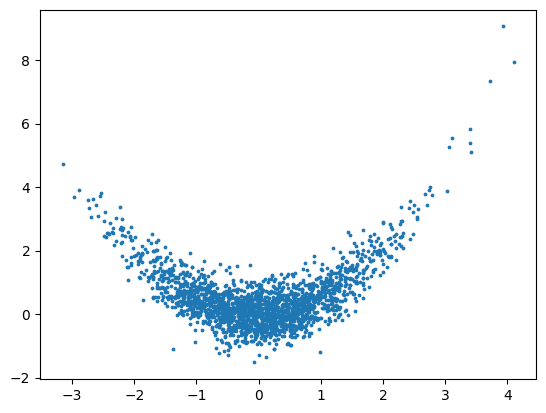

In [ ]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
torch.manual_seed(0)

def log_p(z):
    z1, z2 = z[:, 0], z[:, 1]
    return -0.5 * z1**2 - 0.5 * ((z2 - 0.5 * z1**2) / 0.5)**2

z1 = torch.randn(2000)
z2 = 0.5 * z1**2 + 0.5 * torch.randn(2000)
plt.scatter(z1, z2, s=3)
plt.show()

In [ ]:
mu = torch.zeros(2, requires_grad=True)
log_sigma = torch.zeros(2, requires_grad=True)
opt = torch.optim.Adam([mu, log_sigma], lr=0.05)

for step in range(2000):
    eps = torch.randn(256, 2)
    z = mu + torch.exp(log_sigma) * eps
    log_q = (-0.5 * eps**2 - log_sigma - 0.5 * math.log(2 * math.pi)).sum(1)
    loss = (log_q - log_p(z)).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()

with torch.no_grad():
    gz = mu + torch.exp(log_sigma) * torch.randn(2000, 2)

## Step 3: Implicit generator and discriminator

**Generator G (this is q):** a small neural network that turns random noise
into 2D points. We can sample from it, but we cannot evaluate its density
log q(z).

**Discriminator D:** a small neural network that takes a 2D point and outputs
a score. It is trained to tell points from q apart from points of the target p.
Its output will be used to estimate log q(z) - log p(z), which replaces the
intractable term in the objective.

Here both networks are only defined, not trained. The plot shows the untrained
generator's points next to the target.

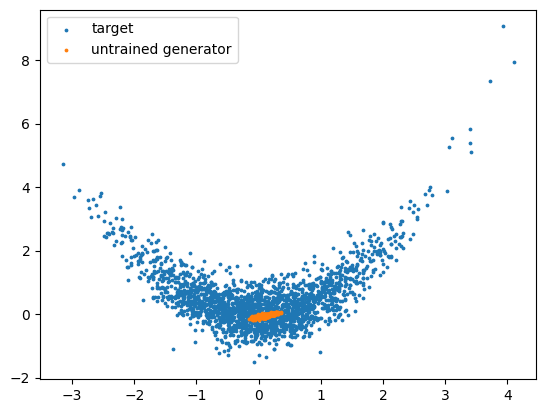

In [ ]:
import torch.nn as nn

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 2),
        )
    def forward(self, eps):
        return self.net(eps)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 1),
        )
    def forward(self, z):
        return self.net(z).squeeze(-1)

G = Generator()
D = Discriminator()

with torch.no_grad():
    gz0 = G(torch.randn(2000, 2))

plt.scatter(z1, z2, s=3, label="target")
plt.scatter(gz0[:, 0], gz0[:, 1], s=3, label="untrained generator")
plt.legend()
plt.show()


## Step 4: Adversarial training loop

We cannot sample from the target p, so the discriminator compares the
generator's points against points from a simple reference distribution r
(a wide Gaussian we can sample from and score).

The discriminator is trained to separate q's points from r's points. Its output
(the logit) then estimates log q(z) - log r(z).

The KL objective can be split as:
E_q[log q - log p] = E_q[ (log q - log r) + (log r - log p) ]

The first part is what D estimates. The second part we can compute directly,
because we have formulas for both r and p. So log q(z) is never evaluated.

The two networks train in alternation: D steps first (to keep the ratio
estimate current), then a G step (to lower the objective).

0 1.4227921962738037 -4.011415004730225
500 0.6381734013557434 -1.5071555376052856
1000 0.47840049862861633 -1.0729024410247803
1500 0.444125771522522 -1.4649540185928345
2000 0.46216410398483276 -1.3052672147750854
2500 0.37932631373405457 -1.4388766288757324
3000 0.4962892532348633 -1.494173526763916
3500 0.5046754479408264 -1.387803316116333
4000 0.4886971712112427 -1.1990214586257935
4500 0.5334696173667908 -0.9792066812515259


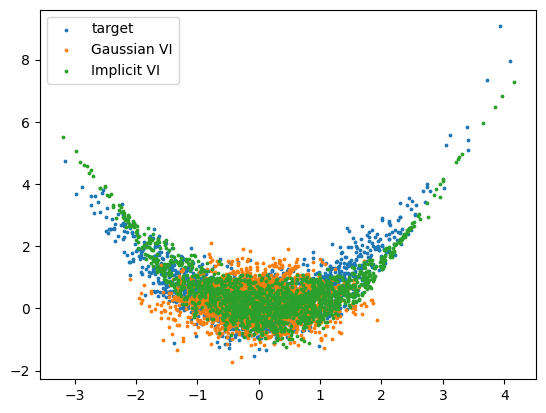

In [ ]:
# --- Implicit VI training ---
G = Generator()
D = Discriminator()
sigma_r = 3.0

def log_r(z):
    return (-0.5 * (z / sigma_r)**2 - math.log(sigma_r) - 0.5 * math.log(2 * math.pi)).sum(1)

optG = torch.optim.Adam(G.parameters(), lr=5e-4)
optD = torch.optim.Adam(D.parameters(), lr=2e-4, weight_decay=1e-3)
bce = nn.BCEWithLogitsLoss()

for step in range(5000):
    for _ in range(2):
        with torch.no_grad():
            zq = G(torch.randn(256, 2))
        zr = sigma_r * torch.randn(256, 2)
        lossD = bce(D(zq), torch.ones(256)) + bce(D(zr), torch.zeros(256))
        optD.zero_grad()
        lossD.backward()
        optD.step()

    zq = G(torch.randn(256, 2))
    Dq = 8.0 * torch.tanh(D(zq) / 8.0)
    lossG = (Dq + log_r(zq) - log_p(zq)).mean()
    optG.zero_grad()
    lossG.backward()
    torch.nn.utils.clip_grad_norm_(G.parameters(), 1.0)
    optG.step()

    if step % 500 == 0:
        print(step, lossD.item(), lossG.item())

with torch.no_grad():
    gz_imp = G(torch.randn(2000, 2))

plt.scatter(z1, z2, s=3, label="target")
plt.scatter(gz[:, 0], gz[:, 1], s=3, label="Gaussian VI")
plt.scatter(gz_imp[:, 0], gz_imp[:, 1], s=3, label="Implicit VI")
plt.legend()
plt.show()

## Step 5: Numeric comparison

A plot alone is not enough, so we also score how close each method's samples
are to the target.

We cannot compute KL(q||p) for the implicit generator, because that needs
log q(z), the very term it cannot evaluate. So we use MMD (maximum mean
discrepancy), which only needs samples. It compares two sets of points and
gives 0 when they look the same. A lower MMD means a better fit.

The target samples are used here only to evaluate the result. The training
itself never sampled from the target.

In [ ]:
target = torch.stack([z1, z2], dim=1)

def mmd(a, b, bw=1.0):
    def k(x, y):
        return torch.exp(-torch.cdist(x, y) ** 2 / (2 * bw ** 2))
    return (k(a, a).mean() + k(b, b).mean() - 2 * k(a, b).mean()).item()

print("MMD Gaussian VI:", mmd(gz, target))
print("MMD Implicit VI:", mmd(gz_imp, target))

MMD Gaussian VI: 0.028949201107025146
MMD Implicit VI: 0.012652873992919922
